# CNN Classification of Vehicle Categories on a Custom Dataset
Name: Md.Fardin Rahman Mridul | Student ID: 22-49521-3 | Course: CVPR | Date:16 November 2026

Objective: Design, train and evaluate a custom CNN (from scratch, in PyTorch) that classifies vehicle images into 5 categories: civilian, taxi, military, police and diplomatic.

In [5]:
import os
import zipfile
import torch
import torchvision
import torchvision.transforms as transforms

from google.colab import files
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

In [6]:
uploaded = files.upload()

Saving archive.zip to archive.zip


In [7]:
import os
import zipfile

zip_filename = list(uploaded.keys())[0]

extract_path = '/content/dataset'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


## 1. Import Libraries
PyTorch and torchvision are used for the model, data loading and transforms. scikit-learn computes the evaluation metrics, matplotlib and seaborn produce the plots, and torchinfo prints the architecture summary. A fixed random seed (42) makes results reproducible.

In [8]:
# ===== 1. IMPORT LIBRARIES =====
!pip install -q torchinfo

import os, glob, random, time, copy, yaml
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)
from torchinfo import summary

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 2. Load and Explore Dataset
**Source:** Custom dataset (my own), stored in YOLO object-detection format (`images/` and `labels/` folders for train, val and test, plus `data_multiclass.yaml`).

**Classes (5):** civilian, taxi, military, police, diplomatic.

**Size:** 2,947 images, split into 2,349 train / 303 validation / 295 test. The split was made duplicate-aware (SHA-256 and perceptual hashing), with no duplicate groups crossing train and validation.

**Conversion to classification:** The dataset has bounding-box labels, so each image is assigned the most frequent class id in its label file. Images with empty labels were skipped (31 in train, 4 in test), leaving 2,318 / 303 / 291 images. A small share of images (about 3%) contain more than one class, so this rule is an approximation.

**Class imbalance:** Civilian is the largest class and taxi the smallest (about 10:1 in training). This is handled with class-weighted loss.

**Limitations:** Image similarity checks cannot guarantee separation by vehicle or camera. The taxi class has only 14 test images, so its metrics are noisy.

In [12]:
# Automatically find the folder containing data_multiclass.yaml
yaml_files = glob.glob("/content/dataset/**/data_multiclass.yaml", recursive=True)
assert len(yaml_files) > 0, "data_multiclass.yaml not found, check your zip structure"
DATA_DIR = os.path.dirname(yaml_files[0])
print("DATA_DIR:", DATA_DIR)
print("Contents:", os.listdir(DATA_DIR))

with open(f"{DATA_DIR}/data_multiclass.yaml") as f:
    cfg = yaml.safe_load(f)
class_names = [cfg["names"][k] for k in sorted(cfg["names"])]
num_classes = cfg["nc"]
print("Classes:", class_names, "| Number of classes:", num_classes)

DATA_DIR: /content/dataset
Contents: ['labels', 'images', 'data_multiclass.yaml', 'split_summary.json']
Classes: ['civilian', 'taxi', 'military', 'police', 'diplomatic'] | Number of classes: 5


In [13]:
class YoloClsDataset(Dataset):
    """Classification dataset built from YOLO-format labels.
    Label of an image = most frequent class id in its .txt file."""
    def __init__(self, root, split, transform=None):
        self.transform = transform
        self.samples = []          # (image_path, class_id)
        skipped = 0
        for img_path in sorted(glob.glob(f"{root}/images/{split}/*")):
            if not img_path.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            stem = os.path.splitext(os.path.basename(img_path))[0]
            lbl_path = f"{root}/labels/{split}/{stem}.txt"
            if not os.path.exists(lbl_path):
                skipped += 1; continue
            with open(lbl_path) as f:
                ids = [int(line.split()[0]) for line in f if line.strip()]
            if not ids:
                skipped += 1; continue
            self.samples.append((img_path, Counter(ids).most_common(1)[0][0]))
        self.targets = [s[1] for s in self.samples]
        print(f"{split}: {len(self.samples)} images (skipped {skipped} empty/unlabelled)")

    def __len__(self): return len(self.samples)

    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, label

**Observations:** The class distribution is clearly imbalanced, with civilian dominating and taxi the rarest class. The sample images show vehicles at different scales, angles and lighting, which motivates the augmentation below.

train: 2318 images (skipped 31 empty/unlabelled)
val: 303 images (skipped 0 empty/unlabelled)
test: 291 images (skipped 4 empty/unlabelled)


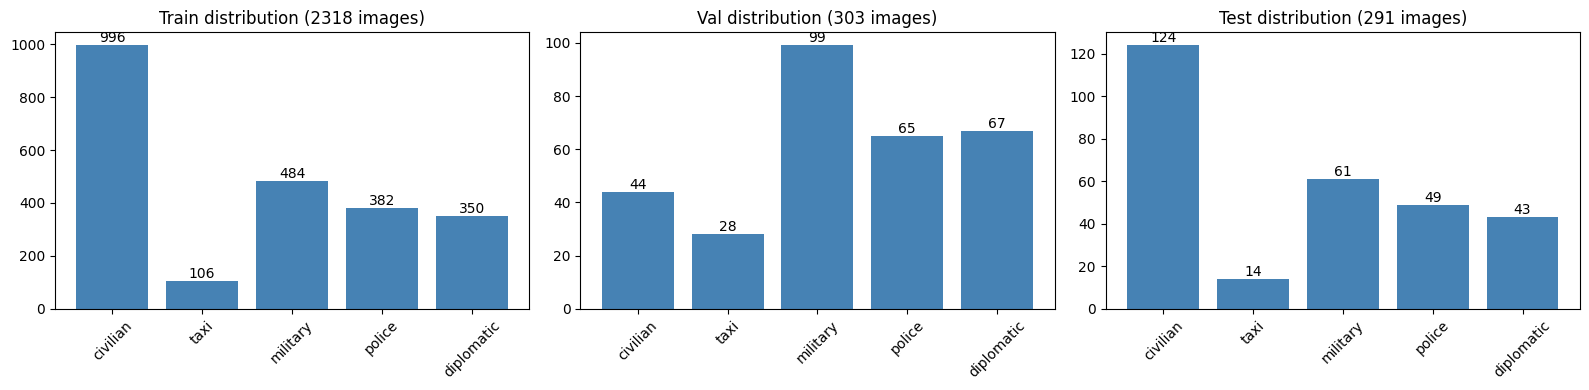

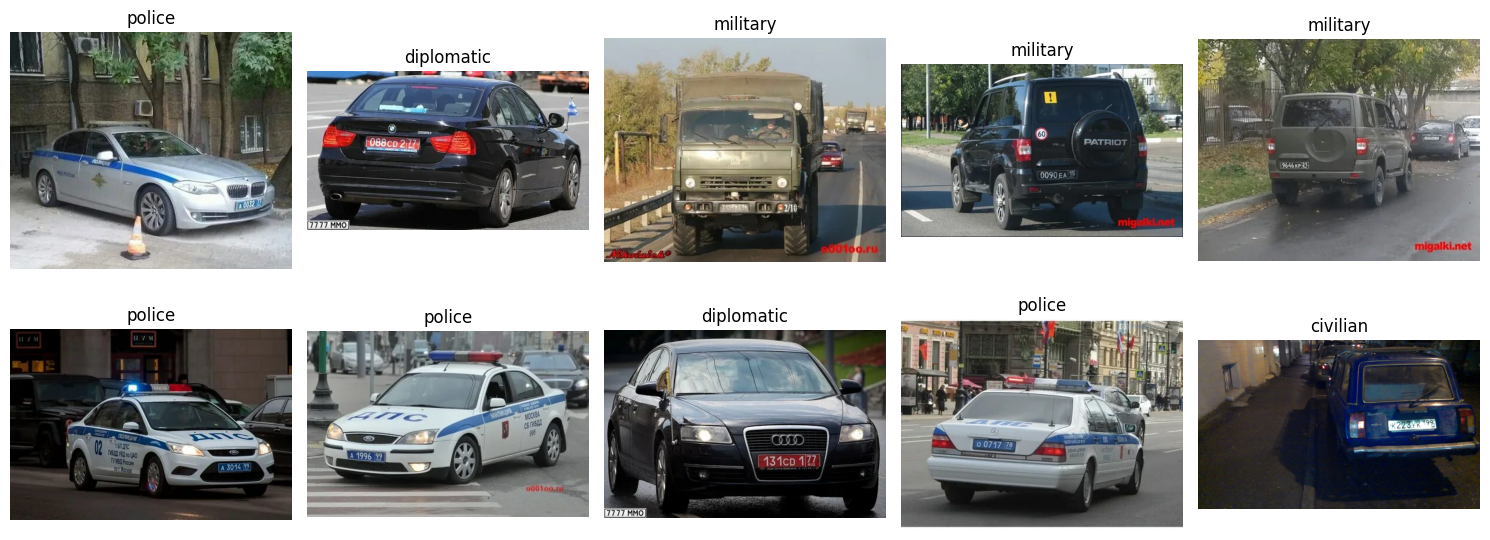

Example image size (W,H): (1200, 800)


In [14]:
raw_train = YoloClsDataset(DATA_DIR, "train")
raw_val   = YoloClsDataset(DATA_DIR, "val")
raw_test  = YoloClsDataset(DATA_DIR, "test")

# Class distribution per split
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (n, d) in zip(ax, [("Train", raw_train), ("Val", raw_val), ("Test", raw_test)]):
    c = np.bincount(d.targets, minlength=num_classes)
    a.bar(class_names, c, color="steelblue")
    a.set_title(f"{n} distribution ({len(d)} images)")
    a.tick_params(axis="x", rotation=45)
    for i, v in enumerate(c): a.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

# Sample images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for a in axes.flat:
    p, l = random.choice(raw_train.samples)
    a.imshow(Image.open(p)); a.set_title(class_names[l]); a.axis("off")
plt.tight_layout(); plt.show()

print("Example image size (W,H):", Image.open(raw_train.samples[0][0]).size)

## 3. Data Preprocessing & Augmentation
- **Resize to 128×128:** a fixed input size is required for batching; 128 balances detail and training speed.
- **Normalization (ImageNet mean/std):** gives inputs a similar scale, which stabilizes and speeds up training.
- **Augmentation (train only):** random horizontal flip, rotation (±15°) and brightness/contrast jitter simulate viewpoint and lighting changes and reduce overfitting.
- **No augmentation on validation/test**, so evaluation reflects real, unmodified images.
- **Batch size 32** and shuffled training data.

In [15]:
# ===== 3. DATA PREPROCESSING & AUGMENTATION =====
IMG_SIZE   = 128
BATCH_SIZE = 32
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([       # no augmentation for val/test
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = YoloClsDataset(DATA_DIR, "train", train_tf)
val_ds   = YoloClsDataset(DATA_DIR, "val",   eval_tf)
test_ds  = YoloClsDataset(DATA_DIR, "test",  eval_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

imgs, lbls = next(iter(train_loader))
print("Batch shape:", imgs.shape, "| Labels:", lbls[:8].tolist())

train: 2318 images (skipped 31 empty/unlabelled)
val: 303 images (skipped 0 empty/unlabelled)
test: 291 images (skipped 4 empty/unlabelled)
Batch shape: torch.Size([32, 3, 128, 128]) | Labels: [0, 0, 3, 0, 0, 4, 0, 3]


## 4. CNN Architecture
The network has 4 convolutional blocks, each Conv(3×3) → BatchNorm → ReLU → MaxPool(2), with filters increasing 32 → 64 → 128 → 256.
- **Increasing filters:** early layers learn simple edges and textures; deeper layers learn complex shapes and parts.
- **BatchNorm:** stabilizes and speeds up training.
- **MaxPool:** reduces spatial size (128 → 8) and adds small translation invariance.
- **Global average pooling:** replaces a large flatten layer, so there are far fewer parameters and less overfitting.
- **Classifier:** Linear(256→128) → ReLU → Dropout(0.5) → Linear(128→5).

In [16]:
# ===== 4. DEFINE CNN ARCHITECTURE =====
class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(
            block(3, 32),      # 128 -> 64
            block(32, 64),     # 64  -> 32
            block(64, 128),    # 32  -> 16
            block(128, 256),   # 16  -> 8
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

model = CustomCNN(num_classes).to(device)
summary(model, input_size=(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE),
        col_names=["input_size", "output_size", "num_params"])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
CustomCNN                                [32, 3, 128, 128]         [32, 5]                   --
├─Sequential: 1-1                        [32, 3, 128, 128]         [32, 256, 8, 8]           --
│    └─Sequential: 2-1                   [32, 3, 128, 128]         [32, 32, 64, 64]          --
│    │    └─Conv2d: 3-1                  [32, 3, 128, 128]         [32, 32, 128, 128]        896
│    │    └─BatchNorm2d: 3-2             [32, 32, 128, 128]        [32, 32, 128, 128]        64
│    │    └─ReLU: 3-3                    [32, 32, 128, 128]        [32, 32, 128, 128]        --
│    │    └─MaxPool2d: 3-4               [32, 32, 128, 128]        [32, 32, 64, 64]          --
│    └─Sequential: 2-2                   [32, 32, 64, 64]          [32, 64, 32, 32]          --
│    │    └─Conv2d: 3-5                  [32, 32, 64, 64]          [32, 64, 64, 64]          18,496
│    │    └─BatchNorm2d: 3-6  

**Model summary:** The model has **422,917 trainable parameters** (about 1.69 MB). Most are in the last convolutional layer (295,168, roughly 70%). Input is [32, 3, 128, 128] and output is [32, 5], one score per class.

## 5. Training and Optimization
| Hyperparameter | Value | Rationale |
|---|---|---|
| Image size | 128×128 | Balance of detail and speed |
| Batch size | 32 | Stable gradients, fits GPU memory |
| Optimizer | Adam | Adaptive learning rate, fast convergence |
| Learning rate | 1e-3 | Standard Adam starting value |
| Weight decay | 1e-4 | L2 regularization |
| Loss | Class-weighted CrossEntropy | Multi-class task plus class imbalance |
| Scheduler | ReduceLROnPlateau (factor 0.5, patience 3) | Lowers LR when validation loss stalls |
| Early stopping | Patience 8 | Prevents overfitting; best weights restored |
| Max epochs | 40 | Upper limit |
| Dropout | 0.5 | Regularization in the classifier |

In [17]:
# ===== 5. TRAINING LOOP WITH VALIDATION =====
EPOCHS       = 40
LR           = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE     = 8     # early stopping

# Class weights (inverse frequency) to handle imbalance
counts = np.bincount(train_ds.targets, minlength=num_classes)
weights = counts.sum() / (num_classes * counts)
class_weights = torch.tensor(weights, dtype=torch.float).to(device)
print("Class weights:", dict(zip(class_names, weights.round(2))))

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss, best_weights, wait = float("inf"), None, 0

start = time.time()
for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step(va_loss)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss {tr_loss:.4f} Acc {tr_acc:.4f} | "
          f"Val Loss {va_loss:.4f} Acc {va_acc:.4f} | "
          f"LR {optimizer.param_groups[0]['lr']:.6f}")

    if va_loss < best_val_loss:
        best_val_loss, best_weights, wait = va_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping triggered."); break

print(f"Training time: {(time.time()-start)/60:.1f} min")
model.load_state_dict(best_weights)   # restore best model

Class weights: {'civilian': np.float64(0.47), 'taxi': np.float64(4.37), 'military': np.float64(0.96), 'police': np.float64(1.21), 'diplomatic': np.float64(1.32)}
Epoch 01/40 | Train Loss 1.2112 Acc 0.4150 | Val Loss 1.3182 Acc 0.3795 | LR 0.001000
Epoch 02/40 | Train Loss 0.9307 Acc 0.6018 | Val Loss 0.8943 Acc 0.6535 | LR 0.001000
Epoch 03/40 | Train Loss 0.7759 Acc 0.6652 | Val Loss 0.7328 Acc 0.7063 | LR 0.001000
Epoch 04/40 | Train Loss 0.7269 Acc 0.7041 | Val Loss 0.8277 Acc 0.7096 | LR 0.001000
Epoch 05/40 | Train Loss 0.6597 Acc 0.7278 | Val Loss 0.6992 Acc 0.7426 | LR 0.001000
Epoch 06/40 | Train Loss 0.5848 Acc 0.7593 | Val Loss 0.6189 Acc 0.7492 | LR 0.001000
Epoch 07/40 | Train Loss 0.5424 Acc 0.7882 | Val Loss 0.6715 Acc 0.7492 | LR 0.001000
Epoch 08/40 | Train Loss 0.5097 Acc 0.8050 | Val Loss 0.7366 Acc 0.7195 | LR 0.001000
Epoch 09/40 | Train Loss 0.4996 Acc 0.7929 | Val Loss 0.5795 Acc 0.7591 | LR 0.001000
Epoch 10/40 | Train Loss 0.4385 Acc 0.8261 | Val Loss 0.4275 Acc

<All keys matched successfully>

Early stopping triggered at epoch 34, and the weights with the lowest validation loss were restored for evaluation.

Test Accuracy: 90.03%
Macro F1:      0.8962

              precision    recall  f1-score   support

    civilian     0.9630    0.8387    0.8966       124
        taxi     0.8125    0.9286    0.8667        14
    military     0.8636    0.9344    0.8976        61
      police     0.9412    0.9796    0.9600        49
  diplomatic     0.8000    0.9302    0.8602        43

    accuracy                         0.9003       291
   macro avg     0.8761    0.9223    0.8962       291
weighted avg     0.9072    0.9003    0.9007       291



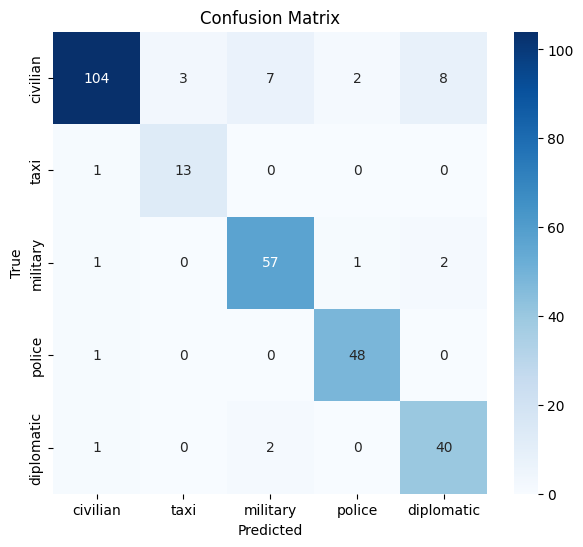

In [18]:
# ===== 6. EVALUATE MODEL ON TEST SET =====
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(y.numpy())

print(f"Test Accuracy: {accuracy_score(all_labels, all_preds)*100:.2f}%")
print(f"Macro F1:      {f1_score(all_labels, all_preds, average='macro'):.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names,
                            labels=range(num_classes), digits=4, zero_division=0))

cm = confusion_matrix(all_labels, all_preds, labels=range(num_classes))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()

## 6. Model Evaluation (Test Set)
**Test accuracy: 90.03%** (262 of 291 images correct), **macro F1: 0.8962**.

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| civilian | 0.9630 | 0.8387 | 0.8966 | 124 |
| taxi | 0.8125 | 0.9286 | 0.8667 | 14 |
| military | 0.8636 | 0.9344 | 0.8976 | 61 |
| police | 0.9412 | 0.9796 | 0.9600 | 49 |
| diplomatic | 0.8000 | 0.9302 | 0.8602 | 43 |

- **Best class: police** (F1 0.96), which is probably visually distinctive.
- **Lowest recall: civilian (0.84).** Of its 20 errors, 8 were predicted as diplomatic, 7 as military, 3 as taxi and 2 as police.
- **Lowest precision: diplomatic (0.80) and taxi (0.81).** Diplomatic gets 10 false positives (8 civilian, 2 military) and taxi gets 3 (all civilian).
- **Recall (macro 0.92) is higher than precision (macro 0.88).** Class weighting makes the model favour minority classes, so it sometimes labels civilian vehicles as a minority class. This is a trade-off for handling imbalance.
- Taxi has only 14 test images, so its scores (one error = 7% recall) are not very reliable.

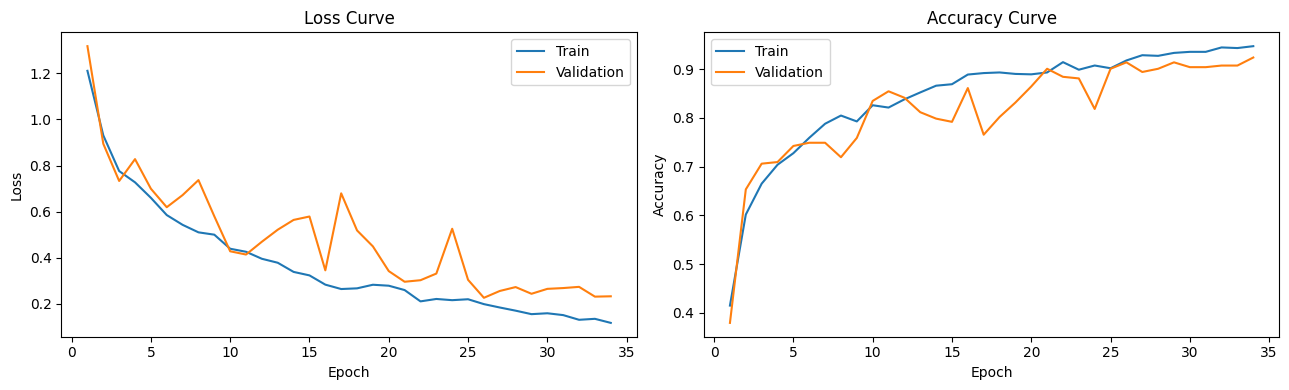

In [19]:
# ===== 7. VISUALIZATIONS =====
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(ep, history["train_loss"], label="Train")
ax[0].plot(ep, history["val_loss"], label="Validation")
ax[0].set_title("Loss Curve"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()

ax[1].plot(ep, history["train_acc"], label="Train")
ax[1].plot(ep, history["val_acc"], label="Validation")
ax[1].set_title("Accuracy Curve"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend()

plt.tight_layout(); plt.show()

## 7. Training and Validation Curves
Training and validation loss decrease steadily, reaching about 0.12 (train) and 0.23 (validation). Accuracy reaches about 95% (train) and 92% (validation). The small gap shows mild overfitting, controlled by augmentation, dropout, weight decay and early stopping. Validation spikes in early epochs come from the high initial learning rate and the small validation set (303 images). They shrink after the scheduler lowers the learning rate. Validation accuracy (~92%) and test accuracy (90.03%) are close, so the model generalizes well.

## 8. Analysis & Discussion
The model reaches 90% test accuracy and 0.90 macro F1 as a small custom CNN trained from scratch (~423K parameters). Errors are concentrated in the civilian class, which is both the largest and the most visually varied, and is confused mainly with diplomatic and military vehicles. This is likely because these categories differ mostly in fine details (such as plate styles or markings) that are partly lost at 128×128 resolution, and because the images are single full-scene photos rather than cropped plates or vehicles. Augmentation, BatchNorm and dropout kept the train-validation gap small. Class weighting improved recall on small classes at the cost of some precision.

## 9. Conclusions & Future Work
**Conclusions:** A custom 4-block CNN classified 5 vehicle categories with 90.03% test accuracy and 0.8962 macro F1, with no severe overfitting. Police was the easiest class and civilian had the lowest recall.

**Future work:** (1) transfer learning with ResNet or EfficientNet, (2) crop bounding boxes for cleaner per-object labels, (3) higher resolution (224×224), (4) more taxi and diplomatic data, (5) Grad-CAM to see what the model looks at, (6) k-fold evaluation for more reliable small-class metrics.

The trained weights are saved as `cnn_model.pth` (about 1.7 MB, well under 20 MB) along with class names and image size. The model is reloaded and verified below.

In [20]:
# ===== SAVE MODEL WEIGHTS =====
SAVE_PATH = "/content/cnn_model.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "img_size": IMG_SIZE,
}, SAVE_PATH)
print("Saved. Size: %.2f MB" % (os.path.getsize(SAVE_PATH) / 1e6))

# Verify loading
ckpt = torch.load(SAVE_PATH, map_location=device)
loaded = CustomCNN(len(ckpt["class_names"])).to(device)
loaded.load_state_dict(ckpt["model_state_dict"])
loaded.eval()
print("Model loaded successfully.")

# Colab storage is wiped when the session ends, so download it now
files.download(SAVE_PATH)

Saved. Size: 1.71 MB
Model loaded successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>